This file will help us find what features are most important via statistics and correlation. Run the script inside this file for the data to appear here, and make sure all data is cleaned properly before proceeding. Feature-target correlation, multi collinearity, model based feature selection and more will be useful here to determine what each feature is useful for.
Contributions by Brendan Daly

In [25]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report

import pymc as pm
import pytensor.tensor as pt
import arviz as az

import logging
# Force Matplotlib's font manager logger to only report critical errors, suppressing info/warnings
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
logging.getLogger("matplotlib").setLevel(logging.ERROR)

In [26]:
# Reproducible by seed number
RANDOM_STATE = 42

## 0. Candidate feature pool

Built from the cleaned tables (`Clean_Data_KNN_Imputation.py` outputs). Three families:

- **Daily milking behavior**: raw daily_milk columns
- **Milk quality channels**: quality table aggregated to cow-day (conductivity is the T4C mastitis channel: ~70 normal, >100 flags clinical mastitis)
- **Per-cow deviations**: each day compared against her own rolling baseline (every cow has unique baselines)

**Experiment with the list below**: anything that exists as a column after this cell is fair game in every section that follows.


In [27]:
# Load cleaned tables
daily = pd.read_csv("data/clean/daily_milk.csv", parse_dates=["Date"])
quality = pd.read_csv("data/clean/quality.csv", parse_dates=["Date Time"])
labels = pd.read_csv("data/clean/hpai_labels.csv")

# Quality table -> one row per cow-day
quality["Date"] = quality["Date Time"].dt.normalize()   # timestamps -> dates, or the join matches nothing
quality["cond_mean"] = quality[["Conductivity LF", "Conductivity RF",
                                "Conductivity LR", "Conductivity RR"]].mean(axis=1)
quality["cond_max"] = quality[["Conductivity LF", "Conductivity RF",
                               "Conductivity LR", "Conductivity RR"]].max(axis=1)
qday = quality.groupby(["cow_ID", "Date"]).agg(
    cond_mean=("cond_mean", "mean"),
    cond_max=("cond_max", "max"),
    milk_temp=("Milk Temperature", "mean"),
).reset_index()

data = daily.merge(qday, on=["cow_ID", "Date"], how="left")

# Per-cow deviation features
data = data.sort_values(["cow_ID", "Date"])
g = data.groupby("cow_ID")
data["prod_dev_7d"] = g["Day Production"].transform(
    lambda s: s - s.shift(1).rolling(7, min_periods=3).mean())
data["prod_drop_1d"] = g["Day Production"].transform(lambda s: s.diff())
data["temp_dev"] = data["milk_temp"] - g["milk_temp"].transform(
    lambda s: s.shift(1).rolling(7, min_periods=3).mean())

# Labels (0 = Negative, 1 = Suspect/Positive)
label_map = labels.dropna(subset=["Cow_ID", "ELISA_Classification"]).set_index("Cow_ID")["ELISA_Classification"].to_dict()
data["y"] = data["cow_ID"].astype(str).map(label_map)

# THE CANDIDATE POOL (edit this chunk)
CANDIDATE_FEATURES = [
    # daily milking behavior
    "Day Production", "Milkings", "Refusals", "Failures",
    "Milkings Avg", "Refusals Avg", "Failures Avg",
    "Rest Feed", "Programmed Rest Feed", "Lactation Days",
    # milk quality channels
    "ISK", "cond_mean", "cond_max", "milk_temp",
    # per-cow deviations
    "prod_dev_7d", "prod_drop_1d", "temp_dev",
    # <-- add more picks here
]

model_data = data.dropna(subset=CANDIDATE_FEATURES + ["y"]).copy()
model_data["y"] = model_data["y"].astype(int)
X_all = model_data[CANDIDATE_FEATURES]
y_all = model_data["y"]
groups_all = model_data["cow_ID"]

print(f"{len(model_data)} cow-days | {groups_all.nunique()} cows | balance: {y_all.value_counts().to_dict()}")

4495 cow-days | 84 cows | balance: {0: 2663, 1: 1832}


## 1. Cow-grouped split

The split happens before any selection so that no information from the test cows influences which features we keep. `GroupShuffleSplit` keeps each cow entirely in train or entirely in test, meaning the honest test is "does this work on cows the model has never seen?" rather than "can this predict every row the model has never seen?"
This section will be irrelevant if, and only if, a model can somehow consider multiple rows together, as the pattern is the important part of early prediction before obvious illness.

In [28]:
train_idx, test_idx = next(GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=RANDOM_STATE
).split(X_all, y_all, groups=groups_all))

X_train, X_test = X_all.iloc[train_idx], X_all.iloc[test_idx]
y_train, y_test = y_all.iloc[train_idx], y_all.iloc[test_idx]

print(f"train: {len(train_idx)} rows / {groups_all.iloc[train_idx].nunique()} cows | "
      f"test: {len(test_idx)} rows / {groups_all.iloc[test_idx].nunique()} cows")

train: 3617 rows / 67 cows | test: 878 rows / 17 cows


## 2. Feature–target relationship

Two complementary lenses:

- **Pearson correlation** with the binary target (point-biserial): detects linear relationships only.
- **Mutual information**: detects any shape of relationship, including nonlinear ones correlation is blind to, but it says nothing about direction.

A feature that scores on both is a strong candidate. A feature with high MI but low correlation has a nonlinear story worth plotting before we can trust it.

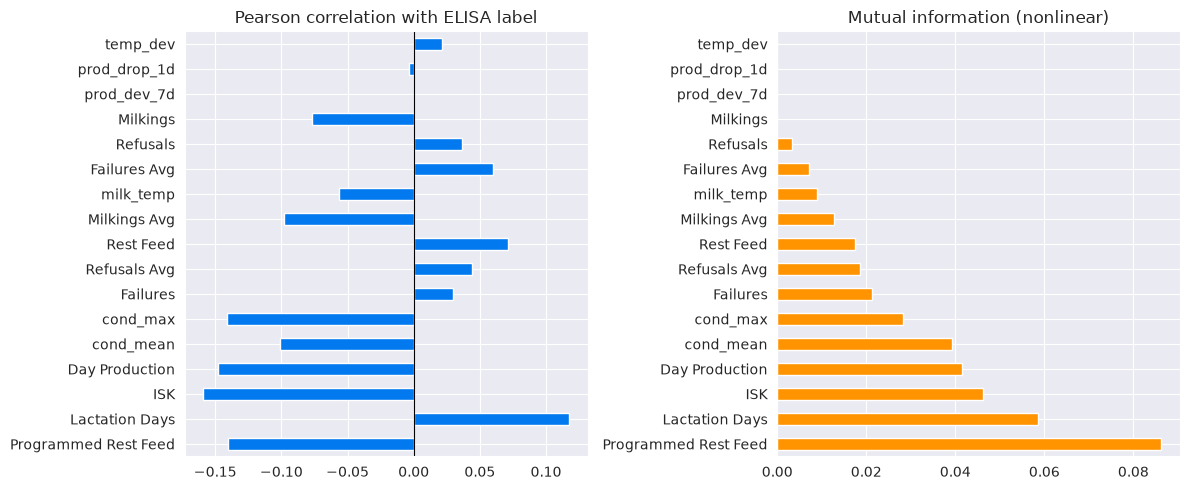

,pearson_corr,mutual_info
Programmed Rest Feed,-0.140,0.086
Lactation Days,0.117,0.059
ISK,-0.159,0.046
Day Production,-0.148,0.042
cond_mean,-0.101,0.039
cond_max,-0.141,0.028
Failures,0.030,0.021
Refusals Avg,0.044,0.019
Rest Feed,0.071,0.018
Milkings Avg,-0.098,0.013


In [29]:
corr_with_target = X_train.corrwith(y_train)
mi = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)

target_relation = pd.DataFrame({
    "pearson_corr": corr_with_target,
    "mutual_info": mi,
}).sort_values("mutual_info", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
target_relation["pearson_corr"].plot.barh(ax=axes[0], color="#0279EE")
axes[0].set_title("Pearson correlation with ELISA label")
axes[0].axvline(0, color="black", linewidth=0.8)
target_relation["mutual_info"].plot.barh(ax=axes[1], color="#FF9400")
axes[1].set_title("Mutual information (nonlinear)")
plt.tight_layout()
plt.savefig("feature_target_relationship.png", dpi=150, bbox_inches="tight")
plt.show()

display(target_relation.round(3))

## 3. Multicollinearity

Two views: pairwise correlation (flags redundant *pairs*) and variance inflation factor (flags features that are linear combinations of *several others at once*).

**What multicollinearity does and does not hurt:**
- **Prediction** (trees, XGBoost): mostly harmless because the model just picks one of the redundant features.
- **Interpretation** (logistic/Bayesian coefficients): seriously distorting because correlated features split the credit.
- **Rule of thumb:** investigate any pair above |0.8|; treat VIF > 10 as a red flag. Drop the less interpretable member of a redundant pair, not a fixed one.

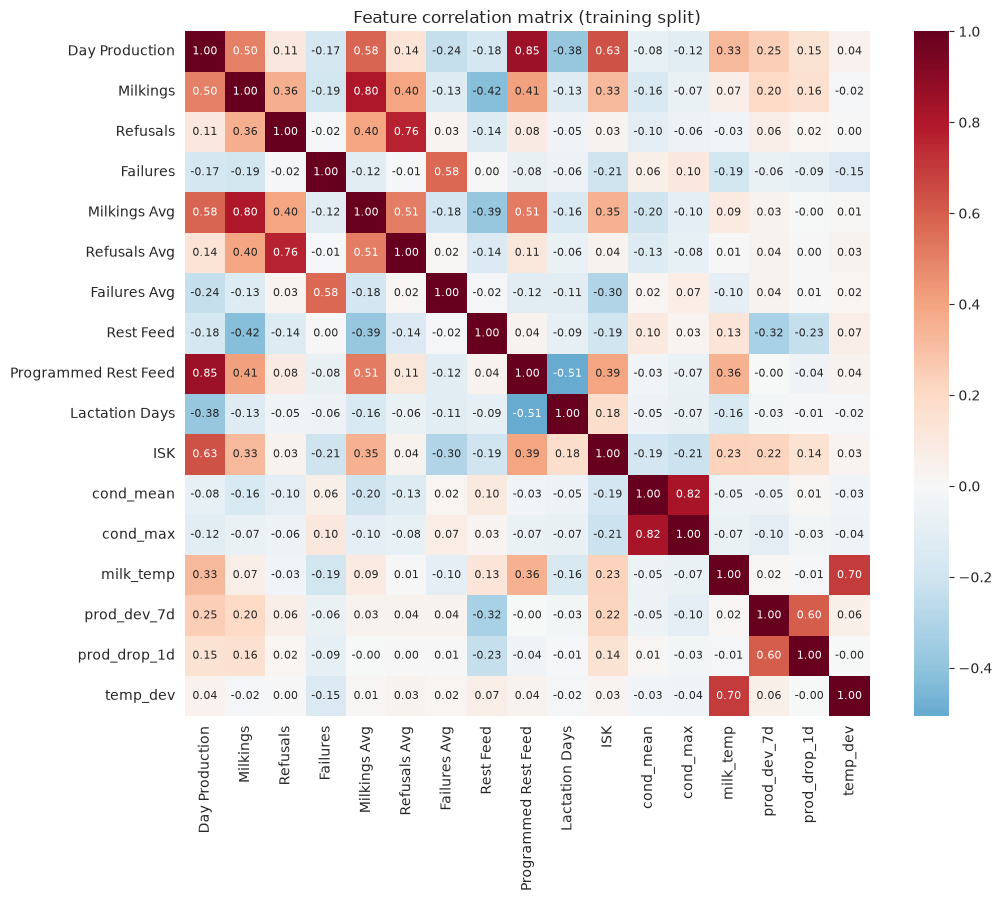

pairs with |r| > 0.8:
  Day Production <-> Programmed Rest Feed: 0.851
  Milkings <-> Milkings Avg: 0.803
  cond_mean <-> cond_max: 0.819


In [30]:
corr_matrix = X_train.corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, annot_kws={"size": 8}, ax=ax)
ax.set_title("Feature correlation matrix (training split)")
plt.tight_layout()
plt.savefig("feature_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# Flag highly correlated pairs
high_pairs = []
for i in range(len(corr_matrix)):
    for j in range(i + 1, len(corr_matrix)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.8:
            high_pairs.append((corr_matrix.index[i], corr_matrix.columns[j], round(r, 3)))
print("pairs with |r| > 0.8:")
for a, b, r in high_pairs:
    print(f"{a} <-> {b}: {r}")
if not high_pairs:
    print("none")

In [31]:
# Variance inflation factor, computed directly (1 / (1 - R^2 of each
# feature regressed on all the others)) -- no extra dependency needed
vif = {}
for column in CANDIDATE_FEATURES:
    others = [c for c in CANDIDATE_FEATURES if c != column]
    regressor = LinearRegression().fit(X_train[others], X_train[column])
    R2 = regressor.score(X_train[others], X_train[column])
    vif[column] = float("inf") if R2 >= 1 else 1 / (1 - R2)

vif_table = pd.Series(vif, name="VIF").sort_values(ascending=False)
print(vif_table.round(2).to_string())
print("\nVIF > 10 = this feature is mostly a linear combination of the others")

Day Production          9.16
Programmed Rest Feed    6.34
Milkings Avg            4.98
cond_mean               3.43
Milkings                3.42
cond_max                3.34
Refusals Avg            2.93
ISK                     2.81
milk_temp               2.73
Refusals                2.47
temp_dev                2.34
prod_dev_7d             2.04
Lactation Days          1.98
Failures Avg            1.77
Failures                1.67
prod_drop_1d            1.63
Rest Feed               1.61

VIF > 10 = this feature is mostly a linear combination of the others


## 4. Model-based selection

Each model type "sees" the data differently, so each nominates different features. Three deliberately different views:

- **4a. L1 logistic regression**: linear footprint; L1 penalty zeroes out weak features. Trust it for linear signals.
- **4b. Random forest + permutation importance**: sees nonlinearities and interactions; permutation importance measures how much test-set recall drops when a feature is shuffled, which is the most honest importance measure.
- **4c. Bayesian logistic (PyMC)**: same linear model as 4a but with uncertainty; a coefficient whose HDI excludes 0 is a feature with credible signal.
- **4d. Add more information here**

### 4a. L1 logistic regression (linear footprint)

In [32]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

l1_model = LogisticRegression(penalty="l1", solver="liblinear", C=0.5, max_iter=5000)
l1_model.fit(X_train_s, y_train)

l1_coefs = pd.Series(l1_model.coef_[0], index=CANDIDATE_FEATURES).sort_values(key=np.abs, ascending=False)
print("L1 coefficients (standardized features; 0 = eliminated by the penalty):")
print(l1_coefs.round(3).to_string())

L1 coefficients (standardized features; 0 = eliminated by the penalty):
ISK                    -0.615
cond_max               -0.471
Day Production          0.426
Lactation Days          0.410
Milkings Avg           -0.198
Programmed Rest Feed   -0.165
Rest Feed               0.157
Refusals Avg            0.152
Milkings                0.084
temp_dev                0.081
milk_temp              -0.073
Failures Avg            0.058
cond_mean               0.045
Failures                0.023
prod_dev_7d             0.021
Refusals                0.014
prod_drop_1d            0.011


C:\Users\Owner\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Owner\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


### 4b. Random forest + permutation importance (nonlinear + interactions)

C:\Users\Owner\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


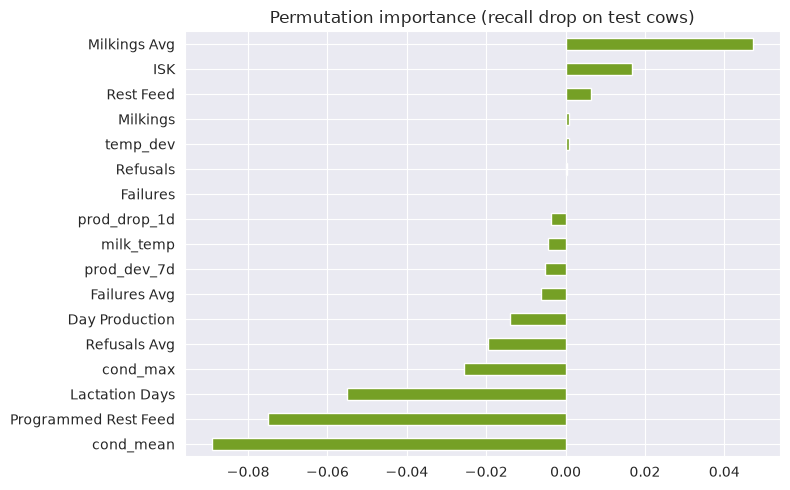

Milkings Avg            0.0472
ISK                     0.0168
Rest Feed               0.0064
Milkings                0.0008
temp_dev                0.0008
Refusals                0.0004
Failures                0.0000
prod_drop_1d           -0.0036
milk_temp              -0.0043
prod_dev_7d            -0.0051
Failures Avg           -0.0062
Day Production         -0.0140
Refusals Avg           -0.0196
cond_max               -0.0255
Lactation Days         -0.0550
Programmed Rest Feed   -0.0750
cond_mean              -0.0891


In [33]:
rf_model = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1
)
rf_model.fit(X_train, y_train)

# Permutation importance: recall drop on TEST cows when each feature is shuffled
perm = permutation_importance(rf_model, X_test, y_test, scoring="recall",
                              n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
perm_table = pd.Series(perm.importances_mean, index=CANDIDATE_FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
perm_table.plot.barh(ax=ax, color="#75A025")
ax.set_title("Permutation importance (recall drop on test cows)")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(perm_table.round(4).to_string())

### 4c. Bayesian logistic regression (uncertainty-aware)

In [36]:
with pm.Model() as feature_model:
    intercept = pm.Normal("intercept", 0, 1.5)
    beta = pm.Normal("beta", 0, 1, shape=X_train_s.shape[1])
    pm.Bernoulli("obs", logit_p=intercept + pt.dot(X_train_s, beta), observed=y_train.to_numpy())
    trace = pm.sample(1000, tune=1000, chains=4, target_accept=0.9,
                      random_state=RANDOM_STATE, progressbar=False)

# Compute mean and 95% credible interval DIRECTLY from the posterior
# samples -- no az.summary column names to break across ArviZ versions
posterior = trace.posterior["beta"].stack(sample=("chain", "draw")).values
bayes_summary = pd.DataFrame({
    "mean": posterior.mean(axis=1),
    "ci_low": np.percentile(posterior, 2.5, axis=1),
    "ci_high": np.percentile(posterior, 97.5, axis=1),
}, index=CANDIDATE_FEATURES)

credible = bayes_summary[(bayes_summary["ci_low"] > 0) | (bayes_summary["ci_high"] < 0)]
print("features with CREDIBLE signal (95% credible interval excludes zero):")
print(credible.round(3).to_string())
print("\nnot credible (HDI includes zero):", [f for f in CANDIDATE_FEATURES if f not in credible.index])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, beta]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 13 seconds.


features with CREDIBLE signal (95% credible interval excludes zero):
                       mean  ci_low  ci_high
Day Production        0.467   0.254    0.682
Milkings Avg         -0.215  -0.375   -0.059
Refusals Avg          0.157   0.040    0.278
Rest Feed             0.167   0.079    0.260
Programmed Rest Feed -0.190  -0.370   -0.020
Lactation Days        0.420   0.317    0.533
ISK                  -0.632  -0.758   -0.510
cond_max             -0.494  -0.650   -0.346

not credible (HDI includes zero): ['Milkings', 'Refusals', 'Failures', 'Failures Avg', 'cond_mean', 'milk_temp', 'prod_dev_7d', 'prod_drop_1d', 'temp_dev']


## 5. Consensus shortlist

Combines every method into one ranking. Each feature gets a rank per method (1 = strongest), the ranks are averaged, and multicollinearity flags are attached. **Low mean rank + no VIF flag = shortlist.**


In [38]:
consensus = pd.DataFrame(index=CANDIDATE_FEATURES)
consensus["corr_rank"] = target_relation["pearson_corr"].abs().rank(ascending=False)
consensus["mi_rank"] = target_relation["mutual_info"].rank(ascending=False)
consensus["l1_rank"] = l1_coefs.abs().rank(ascending=False)
consensus["perm_rank"] = perm_table.rank(ascending=False)
consensus["bayes_credible"] = [f in credible.index for f in CANDIDATE_FEATURES]
consensus["VIF"] = vif_table
consensus["mean_rank"] = consensus[["corr_rank", "mi_rank", "l1_rank", "perm_rank"]].mean(axis=1)
consensus = consensus.sort_values("mean_rank")

print(consensus.round(2).to_string())
print("\n--- SHORTLIST (mean rank in top 8, VIF < 10) ---")
shortlist = consensus[(consensus["mean_rank"] <= 8) & (consensus["VIF"] < 10)]
print(list(shortlist.index))

                      corr_rank  mi_rank  l1_rank  perm_rank  bayes_credible   VIF  mean_rank
ISK                         1.0      3.0      1.0        2.0            True  2.81       1.75
Day Production              2.0      4.0      3.0       12.0            True  9.16       5.25
Milkings Avg                7.0     10.0      5.0        1.0            True  4.98       5.75
cond_max                    3.0      6.0      2.0       14.0            True  3.34       6.25
Lactation Days              5.0      2.0      4.0       15.0            True  1.98       6.50
Programmed Rest Feed        4.0      1.0      6.0       16.0            True  6.34       6.75
Rest Feed                   9.0      9.0      7.0        3.0            True  1.61       7.00
Milkings                    8.0     15.5      9.0        4.0           False  3.42       9.12
cond_mean                   6.0      5.0     13.0       17.0           False  3.43      10.25
Refusals Avg               12.0      8.0      8.0       13.0

## Next Steps

1. **Re-run this notebook after changing the candidate pool.** Selection is cheap and the pipeline is reproducible, so nothing should be simply guessing.
2. **Stability check before trusting a shortlist:** change `RANDOM_STATE` and re-run. Features that appear/disappear across seeds are noise, not signal.
3. **Selection inside cross-validation is the rigorous version.** This notebook selects on one train split, which is fine for exploration, but for the paper-grade number, wrap the entire selection in each CV fold so test cows never influence it.
4. **The label ceiling still applies.** If two feature sets give the same recall, the labels are the bottleneck, not the features. Feature selection optimizes what you extract, but it cannot create what the labels never recorded.
5. **Per-cow deviation features are the ones most likely to be undervalued here.** They are built for *day-level* detection, and these cow-level labels can't reward that. Keep them in the pool for the day the manual labels arrive (labelling each row accurately based on evidence).